# Assignment 1 - Predictive Analytics
**Name:** *Tien Dat Ly*

**Student ID:** *S5411867*

In [4]:
# essential libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
%matplotlib inline
sns.set()

# libraries for clustering & scaling
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering as AC
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

# Use scipy.cluster.hierarchy to draw dendrogram
import scipy.cluster.hierarchy as shc

# Question 1

In [8]:
rp = pd.read_csv("Risk_Profile_26.csv")

In [9]:
rp.head()

,State,Firm Type,Firm,Management Quality,Operational Risk,Compliance Score,Revenue Growth
0,New South Wales,"New South Wales, Medium",NSW Firm 001,37,1.865,4.605,3.045
1,Queensland,"Queensland, Medium",QLD Firm 001,36,2.293,4.486,2.553
2,South Australia,"South Australia, Medium",SA Firm 001,47,2.054,5.161,-3.036
3,Victoria,"Victoria, Medium",VIC Firm 001,42,2.357,4.844,6.033
4,Tasmania,"Tasmania, Large",TAS Firm 001,81,1.486,8.425,1.765


In [10]:
#1
rp.columns = ['State','Type','Firm','Quality','Risk','Score','Growth']
rp.head(3)

,State,Type,Firm,Quality,Risk,Score,Growth
0,New South Wales,"New South Wales, Medium",NSW Firm 001,37,1.865,4.605,3.045
1,Queensland,"Queensland, Medium",QLD Firm 001,36,2.293,4.486,2.553
2,South Australia,"South Australia, Medium",SA Firm 001,47,2.054,5.161,-3.036


In [11]:
#2
pd.get_dummies(rp['State']).head()

,New South Wales,Queensland,South Australia,Tasmania,Victoria,Western Australia
0,True,False,False,False,False,False
1,False,True,False,False,False,False
2,False,False,True,False,False,False
3,False,False,False,False,True,False
4,False,False,False,True,False,False


In [12]:
#2.1
rp.State.value_counts()

State
New South Wales      36
Victoria             32
Queensland           30
Western Australia    12
South Australia       9
Tasmania              2
Name: count, dtype: int64

In [13]:
#2.2
rp.State.value_counts()<=15

State
New South Wales      False
Victoria             False
Queensland           False
Western Australia     True
South Australia       True
Tasmania              True
Name: count, dtype: bool

In [14]:
#2.3
rp.State.value_counts(normalize=True)*100

State
New South Wales      29.752066
Victoria             26.446281
Queensland           24.793388
Western Australia     9.917355
South Australia       7.438017
Tasmania              1.652893
Name: proportion, dtype: float64

In [15]:
#3
rp[(rp.Score >=4) & (rp.Score <=6)]

,State,Type,Firm,Quality,Risk,Score,Growth
0,New South Wales,"New South Wales, Medium",NSW Firm 001,37,1.865,4.605,3.045
1,Queensland,"Queensland, Medium",QLD Firm 001,36,2.293,4.486,2.553
2,South Australia,"South Australia, Medium",SA Firm 001,47,2.054,5.161,-3.036
3,Victoria,"Victoria, Medium",VIC Firm 001,42,2.357,4.844,6.033
6,Victoria,"Victoria, Medium",VIC Firm 002,33,2.463,5.186,2.772
...,...,...,...,...,...,...,...
110,Victoria,"Victoria, Medium",VIC Firm 029,39,3.095,5.309,0.258
111,Queensland,"Queensland, Small",QLD Firm 028,30,2.291,5.145,6.254
112,New South Wales,"New South Wales, Medium",NSW Firm 035,32,2.956,4.438,3.068
117,Victoria,"Victoria, Medium",VIC Firm 031,41,1.948,5.155,6.573


In [16]:
#4
i=rp.groupby('State').Quality.idxmax()
rp.iloc[i,:][['State','Firm','Quality']].sort_values(by='Quality', ascending=False)

,State,Firm,Quality
28,New South Wales,NSW Firm 008,90
76,Tasmania,TAS Firm 002,90
96,Victoria,VIC Firm 025,89
18,Western Australia,WA Firm 001,79
116,South Australia,SA Firm 009,74
13,Queensland,QLD Firm 003,62


In [41]:
#5
rp[['Firm_Region', 'Firm_Size']] = rp['Type'].str.split(',', expand=True)
rp.head()

,State,Type,Firm,Quality,Risk,Score,Growth,Firm_Region,Firm_Size,Score_Cat
0,New South Wales,"New South Wales, Medium",NSW Firm 001,37,1.865,4.605,3.045,New South Wales,Medium,Low
1,Queensland,"Queensland, Medium",QLD Firm 001,36,2.293,4.486,2.553,Queensland,Medium,Low
2,South Australia,"South Australia, Medium",SA Firm 001,47,2.054,5.161,-3.036,South Australia,Medium,Mid
3,Victoria,"Victoria, Medium",VIC Firm 001,42,2.357,4.844,6.033,Victoria,Medium,Low
4,Tasmania,"Tasmania, Large",TAS Firm 001,81,1.486,8.425,1.765,Tasmania,Large,High


Text(0.5, 1.0, 'Boxplot of Risk for each Firm Size')

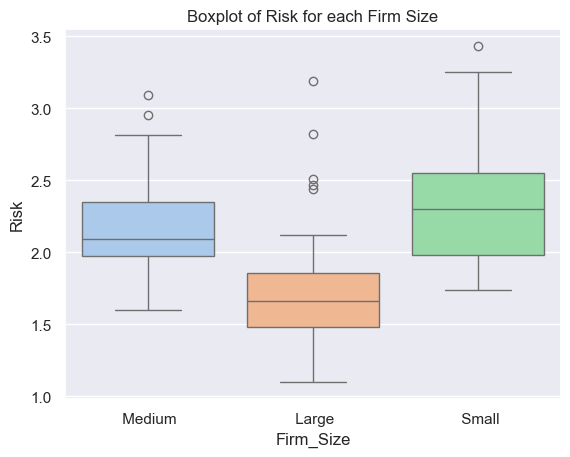

In [43]:
#5
sns.boxplot(x="Firm_Size", y="Risk", data=rp, hue = "Firm_Size", palette='pastel')
plt.title("Boxplot of Risk for each Firm Size")

**5. Comment:**

The boxplot compares the distribution of Risk values across three firm size categories: Medium, Large, and Small. Overall, risk levels vary notably depending on the scale of the firm, with Large firms demonstrating lower risk levels compared to Medium and Small firms.

Small Firms show the highest overall risk, featuring both the highest median (around 2.3) and the largest interquartile range (IQR). Their risk values spread widely, reaching up to around 3.25, with an extreme outlier near 3.4.

Medium Firms exhibit a moderate risk profile, with a median risk level near 2.1. While the central 50% of the data remains relatively tightly clustered between 2.0 and 2.4, there are a couple of high-value outliers approaching 3.0 to 3.1.

Large Firms display the lowest central risk level, centered around a median of approximately 1.7. However, this category contains several upper outliers ranging from around 2.4 up to nearly 3.2, indicating that while most large firms maintain low risk, a few exceptional cases experience significantly elevated risk levels.

In [19]:
rp.Score.idxmax()

35

In [20]:
#6
rp['Score_Cat'] = pd.cut(rp['Score'], bins=[0,5,7,35], labels=['Low','Mid','High'])
rp.head(5)

,State,Type,Firm,Quality,Risk,Score,Growth,Firm_Region,Firm_Size,Score_Cat
0,New South Wales,"New South Wales, Medium",NSW Firm 001,37,1.865,4.605,3.045,New South Wales,Medium,Low
1,Queensland,"Queensland, Medium",QLD Firm 001,36,2.293,4.486,2.553,Queensland,Medium,Low
2,South Australia,"South Australia, Medium",SA Firm 001,47,2.054,5.161,-3.036,South Australia,Medium,Mid
3,Victoria,"Victoria, Medium",VIC Firm 001,42,2.357,4.844,6.033,Victoria,Medium,Low
4,Tasmania,"Tasmania, Large",TAS Firm 001,81,1.486,8.425,1.765,Tasmania,Large,High


Text(0, 0.5, 'Number of firms')

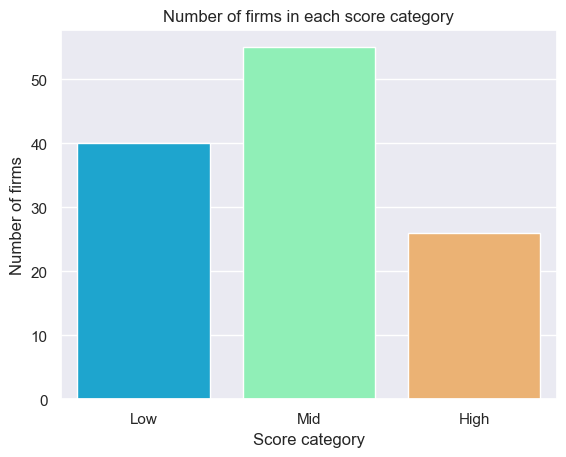

In [44]:
#6
sns.countplot(x='Score_Cat',data=rp, hue = 'Score_Cat', palette='rainbow')
plt.title("Number of firms in each score category")
plt.xlabel("Score category")
plt.ylabel("Number of firms")

# Question 2

In [23]:
#1
scaler = StandardScaler()
rp1 = rp.loc[:,["Risk", "Score", "Growth"]]
rpscale= scaler.fit_transform(rp1)
rpscale=pd.DataFrame(rpscale)
rpscale.describe()

,0,1,2
count,1.210000e+02,1.210000e+02,1.210000e+02
mean,-3.413248e-16,-4.881311e-16,-8.808381e-17
std,1.004158e+00,1.004158e+00,1.004158e+00
min,-2.072078e+00,-2.253311e+00,-4.746601e+00
25%,-7.319477e-01,-7.309577e-01,-5.395809e-01
50%,-1.399486e-01,-2.514419e-01,-1.404602e-02
75%,5.778233e-01,5.574676e-01,5.353768e-01
max,2.989190e+00,2.166542e+00,2.007031e+00


**1. Comment:**

Scaling should be applied prior to distance-based clustering algorithms like K-Means or Hierarchical Clustering. As shown in the table, all features now have a mean of approximately 0 and a standard deviation of approximately 1. Without scaling, variables measured on larger scales or with higher variance would disproportionately influence the distance calculation, causing the algorithm to bias clusters toward those specific variables. Standardization ensures every feature contributes equally to the similarity measurements.

In [24]:
#2
# define a function called Elbow_Curve
# there are two inputs for the function -- X (data) and kmax (maximum number of clusters)
def Elbow_Curve(x, kmax):
 # inertia_: Sum of Squared Distances
 inertia = []

 # no. of clusters
 for k in range(1, kmax+1):
  km = KMeans(n_clusters=k)
  km=km.fit(x)
  inertia.append(km.inertia_)

 # make a line plot of inertia with plt
 fig = plt.figure(figsize=(9, 9))
 #lineplot: plt.plot(x,y,'r-') with red line
 plt.plot(range(1, kmax+1), inertia, 'r-')
 plt.title('Elbow curve')

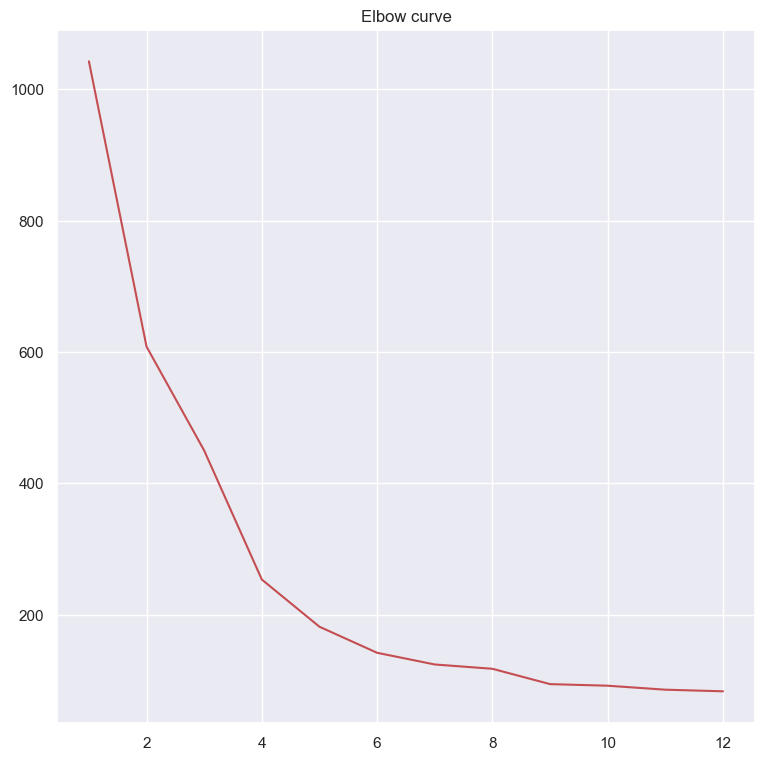

In [25]:
#2
Elbow_Curve(rp1,12)

**2. Comment:**

The optimal number of clusters is k = 4 (or k = 6). The primary elbow occurs at k = 4, where the steep drop in inertia levels off into a noticeably gentler slope. A secondary inflection point appears at k = 6, after which the curve completely flattens out, indicating diminishing returns for adding more clusters. Thus, k = 4 provides the most optimal balance between cluster compactness and model simplicity.

Text(0, 0.5, 'Growth')

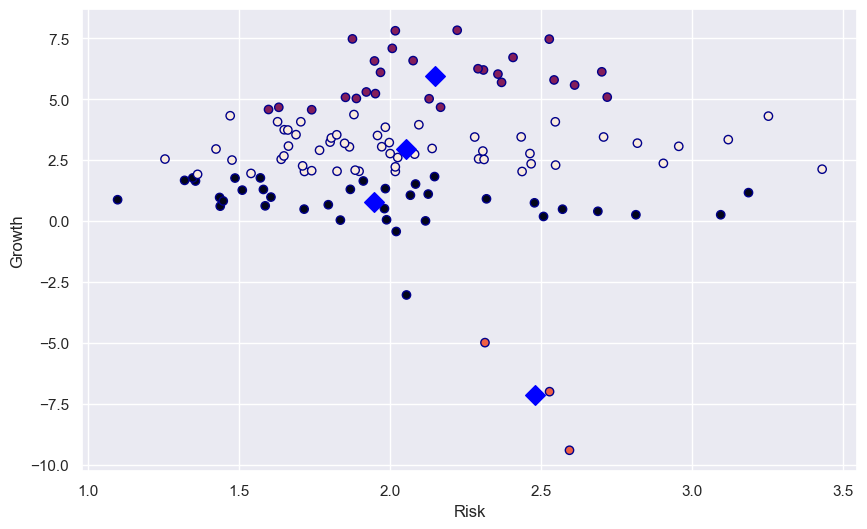

In [26]:
#3
rp3 = rp.loc[:,["Risk","Growth"]]
# cluster size is set to be 4
km = KMeans(n_clusters = 4, random_state=1867)
km.fit(rp3)
km_centers = km.cluster_centers_
# ploting the graph of the clusters
plt.figure(figsize=(10,6))
plt.scatter(x= rp3.iloc[:, 0], y=rp3.iloc[:, 1],c= km.labels_, edgecolor='darkblue')
plt.scatter(x= km_centers[:,0], y=km_centers[:,1], c='blue', marker='D',s=100)
plt.xlabel('Risk')
plt.ylabel('Growth')

**3. Comment:**

The topmost cluster (purple points) represents a high growth, moderate risk group. Centered around a Growth score of approximately 6.0 and a Risk score near 2.15, this segment comprises high-performing firms that achieve substantial growth while incurring average risk levels.

The middle cluster (white points) captures a moderate growth, moderate-to-high risk segment. Centered near a Growth score of 3.0 and Risk of 2.05, it forms the largest cluster, spanning a wide horizontal range of risk levels (from ~1.5 to over 3.4) while maintaining moderate positive growth.

The lower-central cluster (dark navy points) indicates a low growth, broad risk profile. With its centroid situated around a Growth score of 0.8 and Risk near 1.95, these firms exhibit minimal to near-zero growth across a broad spectrum of low to high risk values.

The bottom-right cluster (red points) isolates a small group of severe negative growth, high risk outliers. Centered around a Growth score near -7.0 and a Risk score of 2.48, this cluster clearly separates firms experiencing severe contraction combined with elevated risk from the rest of the dataset.

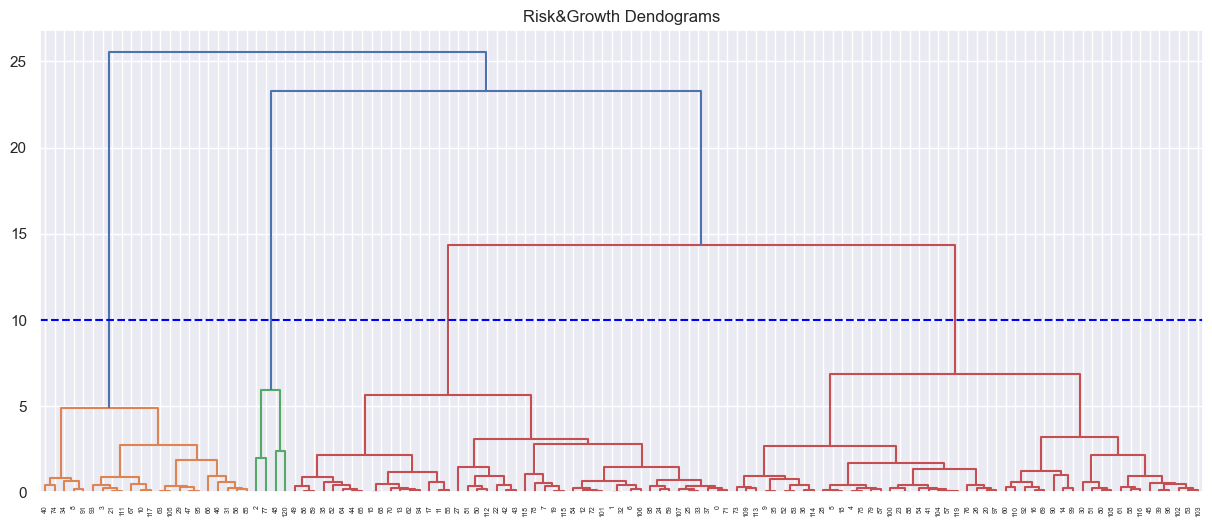

In [27]:
#4
# dendogram plot
plt.figure(figsize=(15, 6))
plt.title("Risk&Growth Dendograms")
# method = "ward" & metric="euclidean"
dend = shc.dendrogram(shc.linkage(rp3, method="ward", metric="euclidean"))
# plot a blue dash line (height: y=180)
plt.axhline(y = 10, color = 'blue', linestyle = '--')

**4. Comment:**

Based on the dendrogram, the optimal number of clusters for Agglomerative Clustering is 4. There is a big drop in the linkage distance around height 10, where the blue dashed horizontal line cuts through four vertical lines. This indicates that partitioning the data into 4 distinct clusters provides the best balance between maximizing between-cluster separation and preserving within-cluster cohesion.

In [28]:
#5
# form 4 clusters with AgglomerativeClustering (AC)
ac = AC(n_clusters=4)
# use fit_predict to get cluster labels
ac.fit_predict(rp3)

array([1, 1, 2, 3, 0, 0, 1, 1, 3, 0, 3, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 3,
       1, 0, 1, 1, 0, 1, 0, 3, 0, 3, 1, 1, 3, 0, 0, 1, 1, 0, 3, 0, 1, 1,
       1, 0, 3, 3, 2, 1, 1, 0, 0, 0, 0, 1, 3, 0, 0, 1, 0, 0, 1, 3, 1, 1,
       3, 3, 1, 0, 1, 1, 1, 0, 3, 0, 0, 2, 1, 0, 0, 1, 1, 0, 1, 3, 1, 0,
       0, 1, 0, 3, 0, 3, 1, 3, 0, 0, 1, 0, 0, 1, 0, 0, 0, 3, 1, 1, 0, 0,
       0, 3, 1, 0, 0, 1, 0, 3, 1, 0, 2])

Text(0, 0.5, 'Growth')

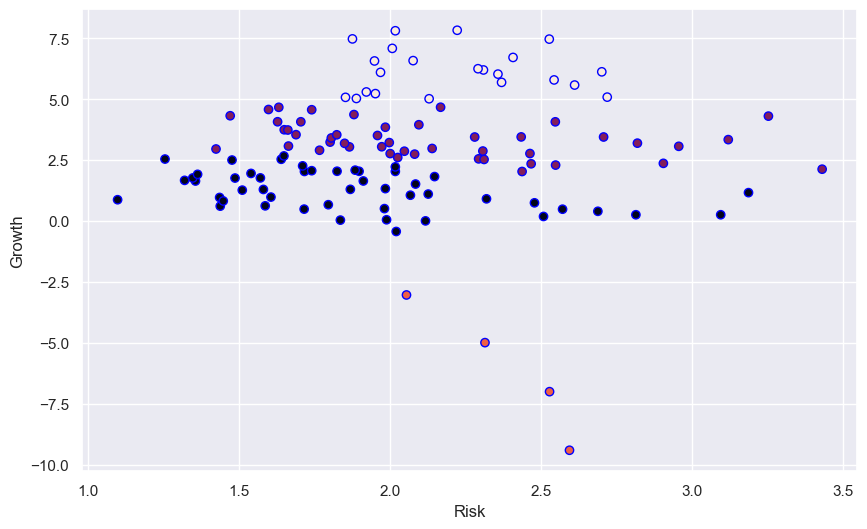

In [45]:
#5
# plot the clusters
plt.figure(figsize=(10,6))
plt.scatter(x= rp3.iloc[:, 0], y=rp3.iloc[:, 1], c=ac.fit_predict(rp3),edgecolor='blue')
plt.xlabel('Risk')
plt.ylabel('Growth')

**5. Comment:**

High growth cluster (white points) gathers firms achieving high growth rates ranging approximately from 5 to nearly 8, spanning moderate risk levels around 1.8 to 2.8.

Moderate growth cluster (purple points) captures firms with moderate growth rates mostly between 2.5 and 5, extending across a wider range of risk levels from about 1.4 to 3.4.

Low growth cluster (blue points) represents the largest group, containing firms concentrated around lower growth rates between 0 and 2.5 across a wide risk spectrum ranging from 1.1 to 3.2.

Severe negative growth cluster (red points) isolated a small set of distinct outlier firms experiencing significant negative growth (from around -3 down to -9.5) alongside elevated risk levels above 2.0.

**6. Comment:**

Both K-Means and Agglomerative Clustering (AC) successfully partition the dataset into four overall risk-growth profiles, exhibiting strong similarities. Both algorithms identify the isolated cluster of extreme negative growth outliers at the bottom and separate the remaining data into low, moderate, and high growth tiers along the vertical axis. Additionally, both methods show that Risk spans broadly across most growth levels rather than driving clear vertical splits. The main difference lies in how the two algorithms define the boundaries between the upper growth tiers. K-Means forms more spherical, distance-to-centroid-based clusters, resulting in a large central group of moderate growth that extends across the entire horizontal range of risk values (~1.5 to 3.4). In contrast, Agglomerative Clustering uses hierarchical link distances, which creates a strictly high growth cluster at the top and places the broad middle band into a single moderate growth group. Consequently, AC produces cleaner horizontal boundary cuts based on Growth thresholds, whereas K-Means clusters are shaped by spatial proximity around central medoids.

# Question 3

In [30]:
gdp = pd.read_excel("GDP_25.xlsx")
health = pd.read_excel("Health_25.xlsx")

In [31]:
gdp.head()

,Country,Country_Code,1960,2025,Region
0,Afghanistan,AFG,NaN,413.757895,Asia
1,Albania,ALB,NaN,8575.171346,Europe
2,Algeria,DZA,238.392477,5364.027950,Africa
3,American Samoa,ASM,NaN,NaN,Oceania
4,Andorra,AND,NaN,46812.448449,Europe


In [32]:
health.head()

,Country,Country_Code,1960,2025,Region
0,Afghanistan,AFG,32.799,66.035,Asia
1,Albania,ALB,56.413,79.602,Europe
2,Algeria,DZA,40.839,76.261,Africa
3,American Samoa,ASM,65.053,72.852,Oceania
4,Andorra,AND,72.094,84.041,Europe


In [33]:
#1
health.describe()

,1960,2025
count,209.000000,211.000000
mean,54.570008,73.664343
std,11.658058,7.058775
min,28.054000,54.462000
25%,44.436000,68.410500
50%,55.153000,74.183780
75%,64.242000,78.749000
max,74.040073,86.372000


**1. Comment:**

Between 1960 and 2025, the overall life expectancy increased significantly while global variability decreased. In 1960, the median life expectancy stood at approximately 55.15 years, with an Interquartile Range of 19.81 years. By 2025, the median life expectancy rose by nearly 19 years to 74.18 years, while the IQR narrowed to 10.34 years. This comparison highlights both a substantial improvement in central overall life expectancy and a tighter grouping around higher ages, reflecting reduced global inequality in life expectancy over time.

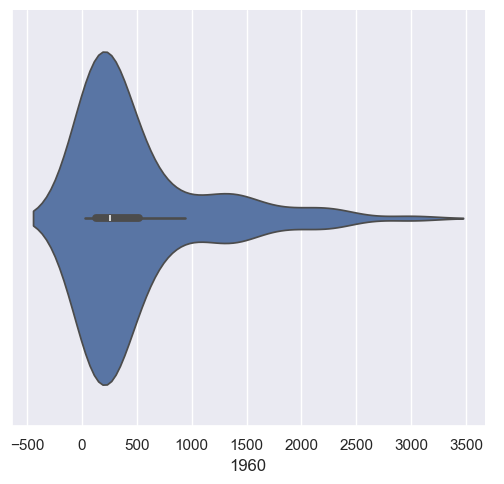

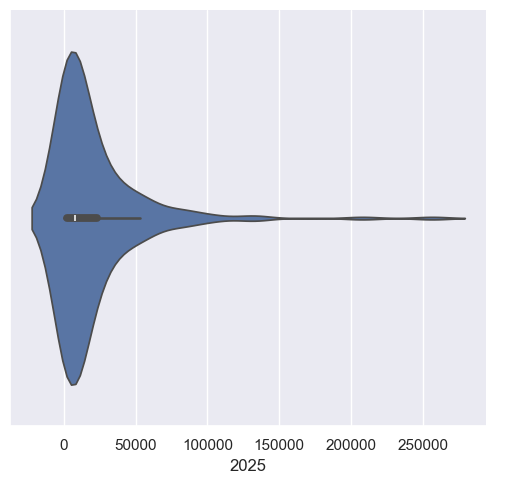

In [34]:
#2
sns.catplot(x= 1960, data=gdp, kind='violin')
sns.catplot(x= 2025, data=gdp, kind='violin')

**2. Comment:**

In 1960, the GDP distribution was tightly clustered at lower values, with the primary density bulked heavily between 0 and 500. The distribution exhibits a mild right tail extending up to around 3,500, indicating that while a few entities had higher economic output, global GDP levels were relatively compact and contained within a narrow absolute range.

By 2025, the overall scale of GDP expanded exponentially, accompanied by extreme right-skewness. The main body of the distribution remains heavily concentrated near lower values (mostly under 25,000 to 50,000), but the right tail stretches dramatically out past 250,000. This extremely long, thin tail reflects immense economic growth among top-tier entities, highlighting a sharp increase in global economic inequality and variance compared to 1960.

In [35]:
#3
mergetable = pd.merge(gdp,health,on=('Country','Country_Code','Region'), how='outer')
mergetable.rename(columns = {'1960_x':'GDP_1960', '2025_x':'GDP_2025','1960_y':'LifeExp_1960', '2025_y':'LifeExp_2025'}, inplace=True)
mergetable

,Country,Country_Code,GDP_1960,GDP_2025,Region,LifeExp_1960,LifeExp_2025
0,Afghanistan,AFG,NaN,413.757895,Asia,32.799000,66.035000
1,Albania,ALB,NaN,8575.171346,Europe,56.413000,79.602000
2,Algeria,DZA,238.392477,5364.027950,Africa,40.839000,76.261000
3,American Samoa,ASM,NaN,NaN,Oceania,65.053000,72.852000
4,Andorra,AND,NaN,46812.448449,Europe,72.094000,84.041000
...,...,...,...,...,...,...,...
206,Virgin Islands (U.S.),VIR,NaN,NaN,Americas,62.743537,80.519512
207,West Bank and Gaza,PSE,NaN,3455.028529,Asia,NaN,65.170000
208,"Yemen, Rep.",YEM,NaN,426.354076,Asia,33.462000,69.295000
209,Zambia,ZMB,221.559849,1330.727806,Africa,50.648000,66.349000


In [46]:
#3
#compute Pearson correlation between two columns by region
mergetable.groupby('Region')[['GDP_1960','LifeExp_1960']].corr()

GDP_1960  LifeExp_1960
Region                                       
Africa   GDP_1960      1.000000      0.307853
         LifeExp_1960  0.307853      1.000000
Americas GDP_1960      1.000000      0.643158
         LifeExp_1960  0.643158      1.000000
Asia     GDP_1960      1.000000      0.544012
         LifeExp_1960  0.544012      1.000000
Europe   GDP_1960      1.000000      0.545412
         LifeExp_1960  0.545412      1.000000
Oceania  GDP_1960      1.000000      0.911188
         LifeExp_1960  0.911188      1.000000

In [47]:
#3
#compute Pearson correlation between two columns by region
mergetable.groupby('Region')[['GDP_2025','LifeExp_2025']].corr()

GDP_2025  LifeExp_2025
Region                                       
Africa   GDP_2025      1.000000      0.566486
         LifeExp_2025  0.566486      1.000000
Americas GDP_2025      1.000000      0.529807
         LifeExp_2025  0.529807      1.000000
Asia     GDP_2025      1.000000      0.752395
         LifeExp_2025  0.752395      1.000000
Europe   GDP_2025      1.000000      0.666643
         LifeExp_2025  0.666643      1.000000
Oceania  GDP_2025      1.000000      0.770261
         LifeExp_2025  0.770261      1.000000

**3. Comment:**

The correlation analysis across regions reveals notable shifts in the strength of the linear relationship between GDP and life expectancy from 1960 to 2025. Overall, every region maintains a positive relationship between economic output and life expectancy across both periods, though the degree of coupling varies significantly by geography and time.

In 1960, the relationship was strongest in Oceania (r = 0.911), indicating a near-perfect linear association between higher GDP and longer life expectancy. The Americas (r = 0.643), Europe (r = 0.545), and Asia (r = 0.544) displayed moderate positive correlations. Conversely, Africa exhibited the weakest correlation (r = 0.308), suggesting that economic output played a relatively minor role in explaining variations in life expectancy across African nations at that time.

By 2025, the regional landscape experienced several key shifts. Asia (r = 0.752) and Africa (r = 0.566) saw significant increases in correlation strength compared to 1960, indicating that growth in GDP became increasingly tied to gains in life expectancy in these developing regions. Europe also showed a moderate rise to r = 0.667. Conversely, Oceania saw its correlation weaken to r = 0.770, and the Americas decreased slightly to r = 0.530, pointing toward diminishing marginal returns on life expectancy as economic output reaches advanced levels.


In [38]:
#4
mergetable['GDP_Increase']= mergetable.GDP_2025 - mergetable.GDP_1960
mergetable.sort_values(by='GDP_Increase', ascending=False).head(5)

,Country,Country_Code,GDP_1960,GDP_2025,Region,LifeExp_1960,LifeExp_2025,GDP_Increase
22,Bermuda,BMU,1715.314632,132604.439086,Americas,66.482000,82.309000,130889.124454
112,Luxembourg,LUX,2261.177418,131407.681365,Europe,68.800561,83.358537,129146.503946
89,Ireland,IRL,706.551022,103887.800388,Europe,70.194268,82.860976,103181.249366
183,Switzerland,CHE,1954.311321,100631.802755,Europe,71.313415,84.056098,98677.491434
143,Norway,NOR,1451.285078,87497.328930,Europe,73.549756,83.112195,86046.043852


In [48]:
#4
mergetable[['GDP_Increase','Region']].groupby('Region').describe()

GDP_Increase                                                          \
                count          mean           std           min           25%   
Region                                                                          
Africa           35.0   2840.177831   3641.244777    121.169205    841.435377   
Americas         31.0  20315.514712  26138.159071   1634.955639   6351.561046   
Asia             21.0  18039.445690  22300.708204    663.847654   2468.536461   
Europe           19.0  58793.085189  29625.174859  12254.764425  40808.460814   
Oceania           4.0  29451.956751  29931.770235   2850.537814   4921.113307   

                                                     
                   50%           75%            max  
Region                                               
Africa     1397.608758   3448.532221   17974.653440  
Americas  13409.231019  21276.745609  130889.124454  
Asia       7092.286738  32963.097153   84984.174162  
Europe    53399.808201  72794.346417  129146.503946  
Oceania   25966.037822  50496.881266   63025.213546

<Axes: xlabel='GDP_2025', ylabel='LifeExp_2025'>

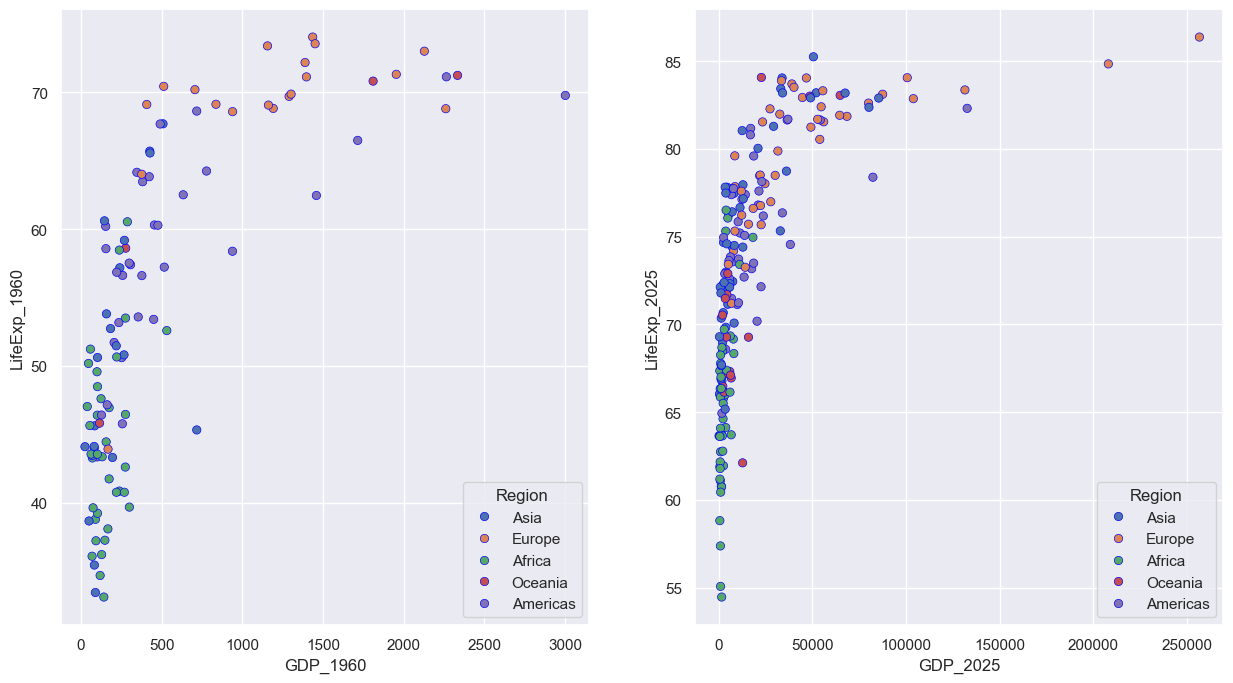

In [40]:
#5
X1960 = mergetable.loc[:, ['GDP_1960', 'LifeExp_1960', 'Region']]
X2025 = mergetable.loc[:, ['GDP_2025', 'LifeExp_2025', 'Region']]

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(15, 8))

sns.scatterplot(data=X1960, x='GDP_1960', y='LifeExp_1960', hue='Region', edgecolor='blue', ax=ax1)
sns.scatterplot(data=X2025, x='GDP_2025', y='LifeExp_2025', hue='Region', edgecolor='blue', ax=ax2)

**5. Comment:**

The two scatter plots reveal several significant changes in the relationship between GDP and life expectancy from 1960 to 2025.

The entire range of life expectancy shifts substantially upward. In 1960, life expectancy spans from under 35 years to around 74 years, whereas by 2025, the minimum life expectancy rises past 54 years, with the upper boundary reaching nearly 87 years. This reflects widespread global improvements in healthcare and standard of living over the 65-year period.

The horizontal GDP axis undergoes an exponential scale expansion. In 1960, GDP values are heavily concentrated below 500, capping out around 3,000. By 2025, overall economic output grows massively, stretching the x-axis past 250,000. Despite this scale expansion, the Preston curve remains intact, where initial increases in GDP correspond to steep gains in life expectancy before flattening out at higher wealth levels.

In 1960, regions are more sharply segregated along the curve: African nations cluster heavily at the bottom with low GDP and life expectancy below 50 years, while European nations occupy the upper tier above 68 years. By 2025, there is clear regional convergence: African and Asian nations show marked improvements in life expectancy, moving up into the 60–75 range, while European and high-income Asian nations converge along the flattened upper plateau above 80 years.